<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#000000; padding:34px 38px 30px 38px; border-radius:14px;">
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#A6A6A6; margin:0; font-size:0.85em; font-weight:600; letter-spacing:0.16em;">DISSIPATIVE PARTICLE DYNAMICS · NOTEBOOK 2 OF 4</p>
<h1 style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:12px 0 14px 0; font-size:2.2em; font-weight:700; line-height:1.15; letter-spacing:-0.01em;">From the Flory–Huggins χ<br>to the DPD repulsion a<sub>ij</sub></h1>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#E0E0E0; margin:0; font-size:1.12em; font-weight:400; line-height:1.55;">Chemistry enters DPD through the repulsion between different bead types. The Flory–Huggins parameter χ of binary DPD mixtures is measured from two-phase slabs, for single beads and for chains, and compared with the mapping of Groot and Warren that sets the repulsions of the block copolymer models of notebooks 03 and 04.</p>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#BDBDBD; margin:18px 0 0 0; font-size:0.95em; font-weight:500;">System: A/B slabs of 3840 beads in 8 × 8 × 20 r<sub>C</sub>³, ρ = 3, a<sub>AA</sub> = a<sub>BB</sub> = 25, Δt = 0.04 τ · programs: NumPy, SciPy</p>
</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The notebook answers four questions:

1. What do the Flory–Huggins parameter χ and its critical point mean for a binary mixture?
2. How does the measured χ of a DPD mixture of single beads depend on Δa = a<sub>AB</sub> − a<sub>AA</sub>?
3. How does χ change when the beads are joined into chains?
4. What happens to a random A/B mixture above the critical point, and what do the repulsions of the coating model say?

The mapping follows section V of Groot and Warren [1]; equations and figures of [1] are cited by their numbers in that
paper. The DPD code is the one of notebook 01, with harmonic springs added. Two exercises with solutions test a
mixture below the critical point and a higher density, and a third asks for a prediction tested in notebook 04. A full
run takes about ten minutes on a laptop or on the Colab CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kourosh-h/dpd-teaching/blob/main/notebooks/02_chi_to_aij.ipynb)

Folders: `figures/` (every plot of the notebook as a PDF file, written when the notebook runs).

<p>Sections: <span style="background-color:#2A9D8F; color:#ffffff; padding:2px 9px; border-radius:10px;">Flory–Huggins</span> <span style="background-color:#3D5A80; color:#ffffff; padding:2px 9px; border-radius:10px;">mapping</span> <span style="background-color:#9C4F6E; color:#ffffff; padding:2px 9px; border-radius:10px;">single beads</span> <span style="background-color:#4F772D; color:#ffffff; padding:2px 9px; border-radius:10px;">chains</span> <span style="background-color:#6B5B95; color:#ffffff; padding:2px 9px; border-radius:10px;">spinodal</span> <span style="background-color:#795548; color:#ffffff; padding:2px 9px; border-radius:10px;">coating model</span> <span style="background-color:#6D597A; color:#ffffff; padding:2px 9px; border-radius:10px;">exercises</span> <span style="background-color:#37474F; color:#ffffff; padding:2px 9px; border-radius:10px;">summary</span> <span style="background-color:#6C757D; color:#ffffff; padding:2px 9px; border-radius:10px;">references</span></p>

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code installs the packages that are missing: NumPy, SciPy, pandas, Matplotlib, and ASE with py3Dmol for the 3D views. After an install, a restart of the kernel may be needed.</div>

In [ ]:
# Installs the packages of this notebook that are missing (on the laptop and on Colab).
# If it installs something and a later import still fails, restart the kernel and run the notebook again.
import importlib
import importlib.util
import subprocess
import sys

PACKAGES = {  # module name: pip package
    'numpy': 'numpy',
    'scipy': 'scipy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'ase': 'ase',
    'py3Dmol': 'py3Dmol',
}
missing = [package for module, package in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    print("installing:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=True)
    importlib.invalidate_caches()
else:
    print("all packages are installed")

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code imports the packages and sets the time step, the friction, the density, the folders, colors and plot settings.</div>

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import brentq
from scipy.spatial import cKDTree

DT = 0.04          # time step (tau)
GAMMA = 4.5        # friction coefficient; noise amplitude zeta = sqrt(2 gamma k_BT) = 3
RHO = 3.0          # bead number density (r_C^-3)

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

# colors of the bead types: A hydrophilic or minority block, B hydrophobic or majority block, B19 hydrophobic
# homopolymer, C substrate, D water; ink: the single-component fluid and the model lines
C = {'A': '#0C54B4', 'B': '#B7371B', 'B19': '#E4840C', 'C': '#795548', 'D': '#2CA02C', 'ink': '#282B28'}

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'], 'pdf.fonttype': 42,
                     'mathtext.default': 'it', 'axes.unicode_minus': False, 'font.size': 10.0,
                     'axes.labelsize': 10.0, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9.0,
                     'axes.linewidth': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelpad': 2.5, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.major.size': 4.2, 'ytick.major.size': 4.2, 'xtick.major.width': 1.0,
                     'ytick.major.width': 1.0, 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,
                     'xtick.minor.width': 0.7, 'ytick.minor.width': 0.7, 'xtick.minor.visible': True,
                     'ytick.minor.visible': True, 'xtick.major.pad': 3.0, 'ytick.major.pad': 3.0,
                     'lines.linewidth': 1.45, 'lines.markersize': 4.25, 'lines.dashed_pattern': [4.0, 2.2],
                     'lines.scale_dashes': False, 'legend.frameon': False, 'legend.handlelength': 1.8,
                     'legend.handletextpad': 0.4, 'legend.columnspacing': 1.6, 'savefig.dpi': 300})


def two_panels(height=2.6):
    """
    Figure 7.0 inches wide with two panels side by side, (a) and (b), 1.61 inches high; a figure higher than 2.6
    inches has more room above the panels, for a legend of two rows.
    """
    fig = plt.figure(figsize=(7.0, height))
    left = fig.add_axes([0.085, 0.429 / height, 0.385, 1.612 / height])
    right = fig.add_axes([0.595, 0.429 / height, 0.385, 1.612 / height])
    left.text(-0.2, 1.03, '(a)', transform=left.transAxes, fontsize=11.0, va='bottom')
    right.text(-0.2, 1.03, '(b)', transform=right.transAxes, fontsize=11.0, va='bottom')
    return fig, left, right


def top_legend(fig, entries):
    """The legend entries in one row at the top of a figure."""
    fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(entries))


def one_panel(height=2.6, left=0.085):
    """Figure 7.0 inches wide with one panel, 1.61 inches high, at the same height as the panels of two_panels."""
    fig = plt.figure(figsize=(7.0, height))
    axes = fig.add_axes([left, 0.429 / height, 0.98 - left, 1.612 / height])
    return fig, axes


def panel_title(axes, text):
    """A short label at the top center of a panel: the name of what it shows."""
    axes.text(0.5, 1.02, text, transform=axes.transAxes, ha='center', va='bottom')

# shades of blue for the repulsion differences of the slab runs, light to dark
DA_COLORS = ['#C6DBEF', '#9ECAE1', '#4292C6', '#2171B5', '#08306B']

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the DPD code of notebook 01 with harmonic springs added, and <code>repulsion</code>, the repulsion matrix of two bead types.</div>

In [3]:
def find_pairs(pos, box):
    """Pairs closer than r_C = 1 (index arrays i < j) and their minimum image vectors r_i - r_j."""
    wrapped = pos % box
    pairs = cKDTree(wrapped, boxsize=box).query_pairs(1.0, output_type='ndarray')
    i, j = pairs[:, 0], pairs[:, 1]
    rij = wrapped[i] - wrapped[j]
    rij -= box * np.round(rij / box)                 # minimum image convention
    return i, j, rij


def dpd_forces(pos, vel, types, a, box, rng, bonds=None, k_bond=2.0, r0=0.0, gamma=GAMMA, kT=1.0, dt=DT):
    """
    Conservative + dissipative + random pair forces (notebook 01) on every bead, plus harmonic springs
    F = -k_bond (r - r0) r_hat between the bonded pairs listed in bonds (an array of index pairs).
    """
    count = len(pos)
    i, j, rij = find_pairs(pos, box)
    r = np.linalg.norm(rij, axis=1)
    unit = rij / r[:, None]
    weight = 1.0 - r
    vij = vel[i] - vel[j]
    pair = (a[types[i], types[j]] * weight - gamma * weight**2 * np.sum(unit * vij, axis=1)
            + np.sqrt(2.0 * gamma * kT) * weight * rng.standard_normal(len(r)) / np.sqrt(dt))
    pair_force = pair[:, None] * unit
    if bonds is not None:
        bi, bj = bonds[:, 0], bonds[:, 1]
        d = pos[bi] - pos[bj]
        d -= box * np.round(d / box)
        length = np.linalg.norm(d, axis=1)
        i, j = np.concatenate([i, bi]), np.concatenate([j, bj])
        pair_force = np.vstack([pair_force, (-k_bond * (length - r0) / length)[:, None] * d])
    force = np.zeros((count, 3))
    for axis in range(3):
        force[:, axis] = np.bincount(i, pair_force[:, axis], count) - np.bincount(j, pair_force[:, axis], count)
    return force


def run(pos, vel, types, a, box, nsteps, bonds=None, k_bond=2.0, r0=0.0, dt=DT, seed=0, every=100,
        callback=None):
    """Groot-Warren modified velocity Verlet with lambda = 1/2 (notebook 01); positions stay unwrapped."""
    rng = np.random.default_rng(seed)
    pos, vel = pos.copy(), vel.copy()
    force = dpd_forces(pos, vel, types, a, box, rng, bonds, k_bond, r0, dt=dt)
    for step in range(1, nsteps + 1):
        pos += dt * vel + 0.5 * dt**2 * force
        new_force = dpd_forces(pos, vel + 0.5 * dt * force, types, a, box, rng, bonds, k_bond, r0, dt=dt)
        vel += 0.5 * dt * (force + new_force)
        force = new_force
        if callback is not None and step % every == 0:
            callback(step, pos, vel)
    return pos, vel


def repulsion(delta_a, a_ii=25.0):
    """Repulsion matrix of two bead types A (0) and B (1) with a_AA = a_BB = a_ii and a_AB = a_ii + delta_a."""
    return np.array([[a_ii, a_ii + delta_a], [a_ii + delta_a, a_ii]])

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>show_3d</code>, which shows a configuration or a trajectory in 3D (drag to rotate, scroll to zoom); the viewers show only while the notebook runs.</div>

In [4]:
# py3Dmol runs on Colab and in Jupyter on the Mac with no widget setup (nglview needs extra setup on Colab)
import py3Dmol
from ase import Atoms


def show_3d(frames, colors, every=1, radius=0.35, width=640, height=420, interval_ms=120):
    """
    Shows one ASE Atoms object, or a list of them (every n-th frame) as a looping movie, with the box edges. The
    bead types are stored as chemical symbols; colors maps each symbol to a color, and symbols not in it are hidden.
    """
    if not isinstance(frames, list):
        frames = [frames]
    frames = frames[::every]
    text = ""
    for frame in frames:  # xyz text with two decimals, which keeps the saved notebook small
        shown = [index for index, symbol in enumerate(frame.get_chemical_symbols()) if symbol in colors]
        text += f"{len(shown)}\n\n"
        for index in shown:
            x, y, z = frame.positions[index]
            text += f"{frame.get_chemical_symbols()[index]} {x:.2f} {y:.2f} {z:.2f}\n"
    view = py3Dmol.view(width=width, height=height)
    view.addModelsAsFrames(text, "xyz")
    for symbol, color in colors.items():
        view.setStyle({"elem": symbol}, {"sphere": {"radius": radius, "color": color}})
    corners = [i * frames[0].cell[0] + j * frames[0].cell[1] + k * frames[0].cell[2]
               for i in (0, 1) for j in (0, 1) for k in (0, 1)]
    for first in range(8):
        for second in range(first + 1, 8):
            if bin(first ^ second).count("1") == 1:  # corners that differ in one direction share an edge
                start = dict(zip("xyz", map(float, corners[first])))
                end = dict(zip("xyz", map(float, corners[second])))
                view.addLine({"start": start, "end": end, "color": "gray"})
    if len(frames) > 1:
        view.animate({"loop": "forward", "interval": interval_ms})
    view.zoomTo()
    view.show()

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#2A9D8F; color:#ffffff; padding:8px 14px; border-radius:6px;">Flory–Huggins theory<br><span style="font-size:0.72em; font-weight:normal;">the free energy of mixing, χ, the binodal, the spinodal and the critical point</span></h2>

Flory–Huggins theory describes a mixture of two components, A and B, on a lattice whose sites are all filled [1, 2].
A molecule of A covers N<sub>A</sub> sites and one of B covers N<sub>B</sub> sites, and φ is the **volume fraction**
of A (the fraction of sites it covers). The free energy of mixing per site is (Eq. 17 of [1])

$$\frac{F_{mix}}{k_BT} = \frac{\phi}{N_A}\ln\phi + \frac{1-\phi}{N_B}\ln(1-\phi) + \chi\,\phi(1-\phi).$$

The first two terms are the **entropy of mixing**, which always favors mixing; it is smaller for chains, since a chain
of N segments moves as one object. The last term is the energy of A–B contacts. The **Flory–Huggins parameter**

$$\chi = \frac{z}{k_BT}\left[\varepsilon_{AB} - \tfrac{1}{2}\left(\varepsilon_{AA} + \varepsilon_{BB}\right)\right],$$

where z is the number of neighbors of a site and ε the contact energies, measures how much A and B dislike each other:
χ > 0 means that A–B contacts cost energy, χ < 0 that they are favored.

For small χ the free energy has one minimum and the mixture is stable. Above a critical value it develops two minima
(Figure 1a), and the mixture splits into an A-rich and a B-rich phase. For a symmetric blend (N<sub>A</sub> =
N<sub>B</sub> = N), the coexisting phases have the fractions φ and 1 − φ, given by the **binodal** (Eq. 18 of [1])

$$\chi N = \frac{\ln\left[(1-\phi)/\phi\right]}{1 - 2\phi} .$$

Inside the **spinodal**, ∂²F/∂φ² < 0, χN > 1/[2φ(1 − φ)], the mixture is unstable to any small fluctuation and demixes
everywhere at once (spinodal decomposition); between the binodal and the spinodal it is metastable and needs a
nucleus. The two curves meet at the **critical point** (Eq. 19 of [1]),

$$\chi_{crit} = \frac{1}{2}\left(\frac{1}{\sqrt{N_A}} + \frac{1}{\sqrt{N_B}}\right)^2 ,$$

which is χ<sub>crit</sub> = 2 for single beads and 2/N for two polymers of equal length N.

**Figure 1.** Flory–Huggins theory for N<sub>A</sub> = N<sub>B</sub> = N: (a) free energy of mixing per site for N = 1
and four values of χ, after Fig. 5 of [1]; (b) the binodal and the spinodal in the plane of φ and χN, with the
critical point. `figures/flory_huggins.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the Flory–Huggins free energy and the binodal, draws Figure 1 (<code>figures/flory_huggins.pdf</code>) and gives χN on the binodal for four minority fractions.</div>

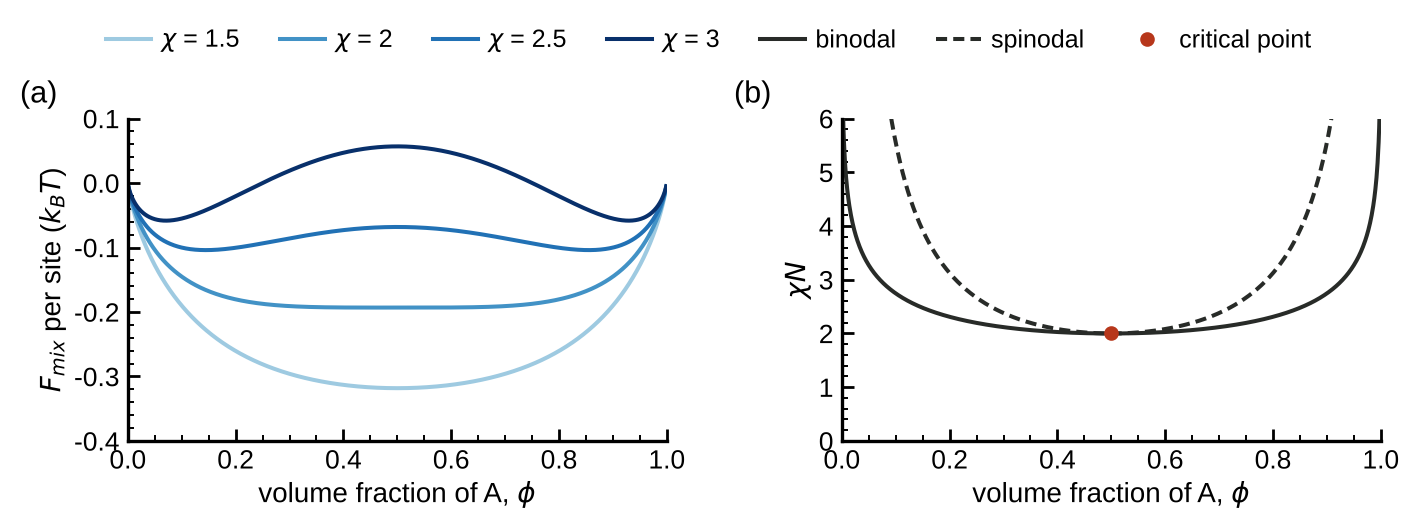

,χN on the binodal
minority fraction φ,
0.30,2.118
0.10,2.747
0.05,3.272
0.01,4.689


In [5]:
def mixing_free_energy(phi, chi, n_a=1, n_b=1):
    """Flory-Huggins free energy of mixing per lattice site (k_BT), Eq. 17 of [1]."""
    return phi / n_a * np.log(phi) + (1 - phi) / n_b * np.log(1 - phi) + chi * phi * (1 - phi)


def binodal_chi(phi):
    """chi N on the binodal of a symmetric blend (N_A = N_B = N) at the coexisting fraction phi, Eq. 18 of [1]."""
    return np.log((1 - phi) / phi) / (1 - 2 * phi)


phi = np.linspace(0.001, 0.999, 999)
fig, left, right = two_panels()
for chi, color in zip([1.5, 2.0, 2.5, 3.0], DA_COLORS[1:]):
    left.plot(phi, mixing_free_energy(phi, chi), color=color)
left.set_xlim(0, 1)
left.set_ylim(-0.4, 0.1)
left.set_xlabel(r'volume fraction of A, $\phi$')
left.set_ylabel(r'$F_{mix}$ per site ($k_BT$)')
side = phi[phi < 0.5]
right.plot(side, binodal_chi(side), color=C['ink'])
right.plot(1 - side, binodal_chi(side), color=C['ink'])
right.plot(phi, 1 / (2 * phi * (1 - phi)), color=C['ink'], ls='--')
right.plot([0.5], [2.0], 'o', color=C['B'])
right.set_xlim(0, 1)
right.set_ylim(0, 6)
right.set_xlabel(r'volume fraction of A, $\phi$')
right.set_ylabel(r'$\chi N$')
entries = [Line2D([], [], color=color, label=f'$\\chi$ = {chi:g}') for chi, color in zip([1.5, 2.0, 2.5, 3.0], DA_COLORS[1:])]
entries += [Line2D([], [], color=C['ink'], label='binodal'), Line2D([], [], color=C['ink'], ls='--', label='spinodal'),
            Line2D([], [], color=C['B'], marker='o', ls='none', label='critical point')]
fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=7)
fig.savefig(FIGURES / 'flory_huggins.pdf')
plt.show()

pd.DataFrame({'χN on the binodal': [binodal_chi(x) for x in [0.3, 0.1, 0.05, 0.01]]},
             index=pd.Index([0.3, 0.1, 0.05, 0.01], name='minority fraction φ')).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Binodal (Figure 1).** A minority fraction of 0.1 in each phase means χN = 2.75, and 0.01 means χN = 4.69:
  far from the critical point, the minority fraction falls roughly as exp(−χN). This makes the binodal a way to
  measure χ: run a two-phase system and read the composition of the phases.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#3D5A80; color:#ffffff; padding:8px 14px; border-radius:6px;">The Groot–Warren mapping<br><span style="font-size:0.72em; font-weight:normal;">why χ is proportional to the repulsion difference Δa</span></h2>

Groot and Warren [1] noticed that the DPD fluid is close to the Flory–Huggins lattice model: it is nearly
incompressible (κ<sup>−1</sup> ≈ 16, notebook 01) and its excess pressure is quadratic in the density. The pressure
p = ρk<sub>B</sub>T + αaρ² corresponds to the free energy density (Eq. 20 of [1])

$$\frac{f_V}{k_BT} = \rho\ln\rho - \rho + \frac{\alpha a \rho^2}{k_BT} ,$$

and for a mixture of A and B with a<sub>AA</sub> = a<sub>BB</sub> at a nearly constant total density ρ = ρ<sub>A</sub> +
ρ<sub>B</sub>, the quadratic term becomes the χφ(1 − φ) term of Flory–Huggins with (Eq. 23 of [1])

$$\chi = \frac{2\alpha\,(a_{AB} - a_{AA})\,\rho}{k_BT} = \frac{2\alpha\,\Delta a\,\rho}{k_BT} .$$

So χ should be proportional to Δa. Groot and Warren tested this with two-phase slabs, read χ from the binodal, and
found the linear relation for χ > 3, where mean-field theory should hold, but with a smaller slope than Eq. 23 (which
gives 0.606 Δa at ρ = 3), and a slope that is not linear in the density (Eq. 24 of [1]):

$$\chi = (0.286 \pm 0.002)\,\Delta a \quad (\rho = 3), \qquad \chi = (0.689 \pm 0.002)\,\Delta a \quad (\rho = 5).$$

For chains of N = 2 to 10 beads they found a slightly larger slope (Eq. 27 of [1]), χ = (0.306 ± 0.003) Δa. Its
inverse is the relation used in polymer models, also by Groot and Madden [3] (their Eq. 7) and in the coating models
of [4–6]:

$$a_{ij} \approx a_{ii} + 3.27\,\chi_{ij} \qquad (\rho = 3).$$

A χ known for a pair of chemistries, from experiment or from atomistic simulation, then gives the DPD repulsion.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#9C4F6E; color:#ffffff; padding:8px 14px; border-radius:6px;">χ of single beads<br><span style="font-size:0.72em; font-weight:normal;">two-phase slabs at five values of Δa, Figs. 6 and 7 of [1]</span></h2>

The slabs follow section V of [1]: a box of 8 × 8 × 20 r<sub>C</sub>³ with 3840 beads at ρ = 3, A beads in the lower
half and B beads in the upper half at the start. The periodic box has two flat interfaces, at z = 10 and across the
boundary at z = 0, and two bulk regions, 2.5 < z < 7.5 and 12.5 < z < 17.5, where the minority fraction φ is read.
Each run has 3000 steps (120 τ); the profiles are averaged after the first 500 steps (Groot and Warren averaged over
10⁵ steps). χ follows from the binodal with N = 1. Δa runs from 8 to 20; the fit through the origin uses only the
points with χ > 3, as in [1].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code sets up the slab box and defines the density profiles and <code>measure_chi</code>, which runs a slab and returns the profiles, φ and χ.</div>

In [6]:
box = np.array([8.0, 8.0, 20.0])                     # the slab box of [1]: 3840 beads at rho = 3
count = int(RHO * np.prod(box))
pos0 = np.random.default_rng(0).random((count, 3)) * box
vel0 = np.random.default_rng(1).standard_normal((count, 3))
vel0 -= vel0.mean(axis=0)
types0 = (pos0[:, 2] > box[2] / 2).astype(int)      # 0 = A in the lower half, 1 = B in the upper half


def bulk_regions(length):
    """Centers of the 40 slices along z, and the middle of each half (a quarter of a half from the interfaces)."""
    edges = np.linspace(0, length, 41)
    centers = 0.5 * (edges[1:] + edges[:-1])
    bulk_a = (centers > length / 8) & (centers < 3 * length / 8)
    bulk_b = (centers > 5 * length / 8) & (centers < 7 * length / 8)
    return centers, bulk_a, bulk_b


CENTERS, BULK_A, BULK_B = bulk_regions(box[2])       # for box[2] = 20: 2.5 to 7.5 and 12.5 to 17.5 r_C


def density_profiles(pos, types, box_now):
    """Number densities of A and B (r_C^-3) in 40 slices along z."""
    z = pos[:, 2] % box_now[2]
    slice_volume = box_now[0] * box_now[1] * box_now[2] / 40
    edges = np.linspace(0, box_now[2], 41)
    density_a = np.histogram(z[types == 0], edges)[0] / slice_volume
    density_b = np.histogram(z[types == 1], edges)[0] / slice_volume
    return density_a, density_b


def measure_chi(pos, vel, types, a, box_now, bonds=None, chain=1, nsteps=3000, discard=500, seed=2):
    """
    Runs a two-phase slab and returns the mean density profiles of A and B, the minority fraction phi in the two
    bulk regions and chi from the binodal of Eq. 18 of [1] (chi N for chains of N beads).
    """
    profiles_a, profiles_b = [], []

    def collect(step, pos_now, vel_now):
        if step > discard:
            density_a, density_b = density_profiles(pos_now, types, box_now)
            profiles_a.append(density_a)
            profiles_b.append(density_b)

    run(pos, vel, types, a, box_now, nsteps, bonds=bonds, every=20, callback=collect, seed=seed)
    density_a, density_b = np.mean(profiles_a, axis=0), np.mean(profiles_b, axis=0)
    fraction_a = density_a / (density_a + density_b)
    centers, bulk_a, bulk_b = bulk_regions(box_now[2])
    phi = 0.5 * (1 - fraction_a[bulk_a].mean() + fraction_a[bulk_b].mean())
    return density_a, density_b, phi, binodal_chi(phi) / chain

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code measures χ for Δa = 8, 10, 12, 15 and 20.</div>

In [7]:
results = {}
start = time.time()
for delta_a in [8.0, 10.0, 12.0, 15.0, 20.0]:
    results[delta_a] = measure_chi(pos0, vel0, types0, repulsion(delta_a), box)
    print(f'delta a = {delta_a:4.1f}: minority fraction {results[delta_a][2]:.4f}, chi = {results[delta_a][3]:.2f}')
print(f'{time.time() - start:.0f} s')

delta a =  8.0: minority fraction 0.1232, chi = 2.60


delta a = 10.0: minority fraction 0.0679, chi = 3.03


delta a = 12.0: minority fraction 0.0340, chi = 3.59


delta a = 15.0: minority fraction 0.0133, chi = 4.42


delta a = 20.0: minority fraction 0.0029, chi = 5.89
198 s


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 2.** Two-phase slabs of single beads: (a) local fraction of A along the box for the five values of Δa
(darker for larger Δa); (b) measured χ against Δa (open circles), the fit through the origin of the points with χ > 3
and Eq. 24 of [1] (dashed). `figures/chi_single_beads.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code fits χ against Δa and draws Figure 2 (<code>figures/chi_single_beads.pdf</code>); the table gives φ and χ of each run.</div>

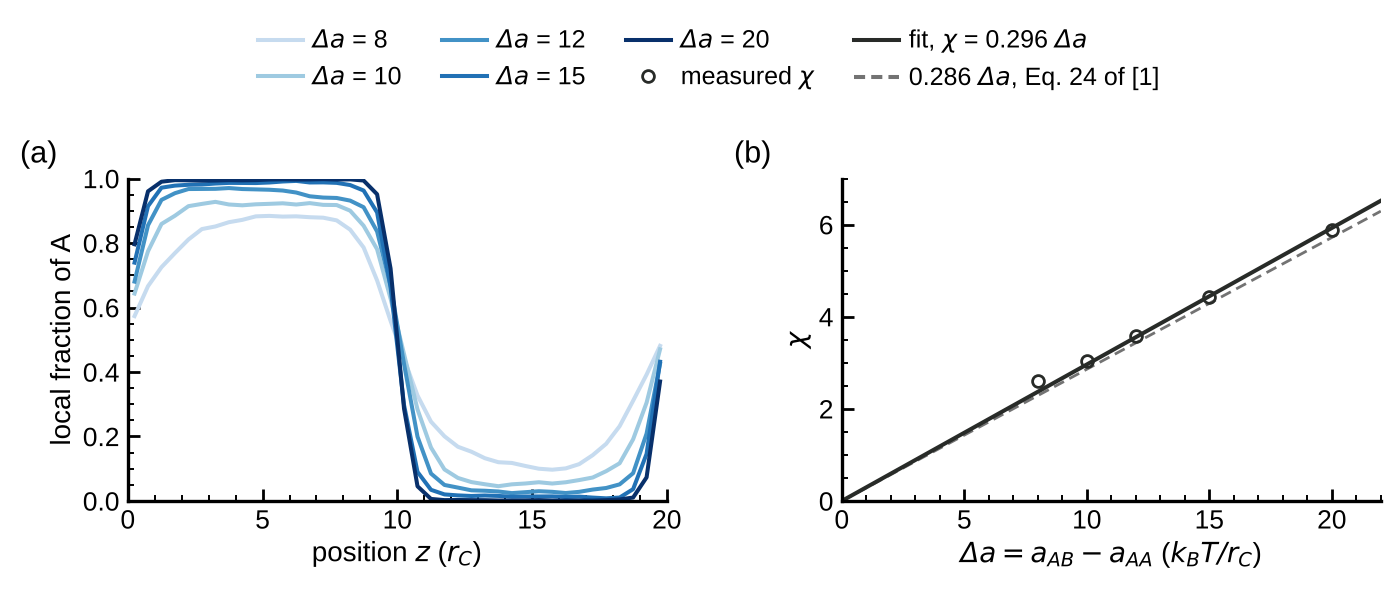

,minority fraction φ,χ,χ / Δa,0.286 Δa
Δa,,,,
8.0,0.1232,2.6040,0.3255,2.288
10.0,0.0679,3.0316,0.3032,2.860
12.0,0.0340,3.5898,0.2991,3.432
15.0,0.0133,4.4233,0.2949,4.290
20.0,0.0029,5.8872,0.2944,5.720


In [8]:
deltas = np.array(list(results))
chis = np.array([results[delta_a][3] for delta_a in deltas])
mean_field = chis > 3                                # Groot and Warren fitted only chi > 3
slope = np.sum(deltas[mean_field] * chis[mean_field]) / np.sum(deltas[mean_field]**2)    # through the origin
line = np.linspace(0, 22, 50)

fig, left, right = two_panels(height=2.9)
for (delta_a, (density_a, density_b, phi_m, chi_m)), color in zip(results.items(), DA_COLORS):
    left.plot(CENTERS, density_a / (density_a + density_b), color=color)
left.set_xlim(0, box[2])
left.set_ylim(0, 1)
left.set_xlabel(r'position $z$ ($r_C$)')
left.set_ylabel('local fraction of A')
right.plot(line, 0.286 * line, color='0.45', lw=1.0, ls='--')
right.plot(line, slope * line, color=C['ink'])
right.plot(deltas, chis, 'o', color=C['ink'], mfc='none', mew=1.0)
right.set_xlim(0, 22)
right.set_ylim(0, 7)
right.set_xlabel(r'$\Delta a = a_{AB} - a_{AA}$ ($k_BT/r_C$)')
right.set_ylabel(r'$\chi$')
entries = [Line2D([], [], color=color, label=f'$\\Delta a$ = {delta_a:g}') for delta_a, color in zip(results, DA_COLORS)]
entries += [Line2D([], [], color=C['ink'], marker='o', mfc='none', ls='none', label=r'measured $\chi$'),
            Line2D([], [], color=C['ink'], label=f'fit, $\\chi$ = {slope:.3f} $\\Delta a$'),
            Line2D([], [], color='0.45', ls='--', label=r'0.286 $\Delta a$, Eq. 24 of [1]')]
fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=4)
fig.savefig(FIGURES / 'chi_single_beads.pdf')
plt.show()

pd.DataFrame({'minority fraction φ': [results[delta_a][2] for delta_a in deltas], 'χ': chis,
              'χ / Δa': chis / deltas, '0.286 Δa': 0.286 * deltas},
             index=pd.Index(deltas, name='Δa')).round(4)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 3.** Density profiles of A, B and their sum across the slab at Δa = 12 (a<sub>AB</sub> = 37), the case of
Fig. 6 of [1]. `figures/density_profile.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 3 (<code>figures/density_profile.pdf</code>); the table gives the total density in the bulk and at the middle interface.</div>

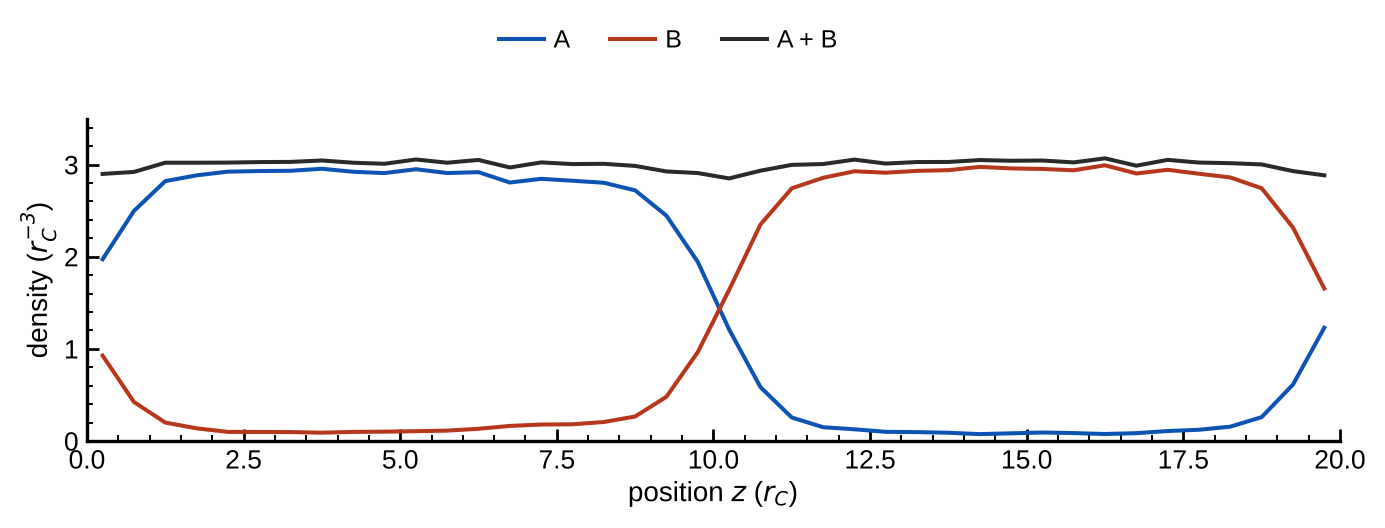

,total density (r_C⁻³)
bulk regions,3.029
lowest value at the middle interface,2.850


In [9]:
density_a, density_b = results[12.0][0], results[12.0][1]
fig, axes = one_panel()
axes.plot(CENTERS, density_a, color=C['A'])
axes.plot(CENTERS, density_b, color=C['B'])
axes.plot(CENTERS, density_a + density_b, color=C['ink'])
axes.set_xlim(0, box[2])
axes.set_ylim(0, 3.5)
axes.set_xlabel(r'position $z$ ($r_C$)')
axes.set_ylabel(r'density ($r_C^{-3}$)')
top_legend(fig, [Line2D([], [], color=C['A'], label='A'), Line2D([], [], color=C['B'], label='B'),
                 Line2D([], [], color=C['ink'], label='A + B')])
fig.savefig(FIGURES / 'density_profile.pdf')
plt.show()

total = density_a + density_b
interface = np.abs(CENTERS - 10.0) < 1.0
pd.DataFrame({'total density (r_C⁻³)': [total[BULK_A | BULK_B].mean(), total[interface].min()]},
             index=['bulk regions', 'lowest value at the middle interface']).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Measured χ (Figure 2).** χ grows linearly with Δa, from 2.60 at Δa = 8 to 5.89 at Δa = 20. The fit of the
  points with χ > 3 gives χ = 0.296 Δa, against 0.286 Δa in [1], and about half of the mean-field prediction of
  Eq. 23. The point at Δa = 8 (χ = 2.60) lies close to the critical point, where the mean-field binodal is not
  expected to hold; Groot and Warren also found the critical point of single beads above the mean-field value of 2.
- **Interface (Figure 3).** The total density dips at the A–B interface, from 3.03 in the bulk to 2.85, the
  small dip that [1] notes in its Fig. 6: beads of the two types avoid each other, and fewer pairs sit across the
  interface.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#4F772D; color:#ffffff; padding:8px 14px; border-radius:6px;">χ of chains<br><span style="font-size:0.72em; font-weight:normal;">two-phase slabs of chains of 2, 4 and 8 beads, Fig. 8 of [1]</span></h2>

Joining beads into chains lowers the entropy of mixing, and polymers demix at a much smaller χ (χ<sub>crit</sub> = 2/N).
Groot and Warren [1] built chains with harmonic springs, F = −C r<sub>ij</sub> between bonded beads, with C = 2: the
mean bonded distance then sits near the maximum of g(r) (notebook 01). They measured χ of chains from the binodal with
N<sub>A</sub> = N<sub>B</sub> = N and found χN k<sub>B</sub>T/Δa = 0.306 N for 2 ≤ N ≤ 10, about 7 % above the single
beads (their Fig. 8). The same slab is used here for A<sub>N</sub> and B<sub>N</sub> chains of N = 2, 4 and 8, with Δa
chosen so that χN ≈ 5 (8, 4 and 2) and with 4000 steps per run, since chains need longer to exchange between the
phases.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code builds the chain slabs and measures χ for N = 2, 4 and 8.</div>

In [10]:
def chain_slab(chain, seed=3):
    """A_N chains in the lower half and B_N chains in the upper half of the slab box, and their bonds."""
    rng = np.random.default_rng(seed)
    chains = count // chain
    pos, types, bonds = [], [], []
    for index in range(chains):
        kind = 0 if index < chains // 2 else 1
        bead = rng.random(3) * box
        bead[2] = rng.uniform(0.5, 9.5) + 10.0 * kind
        for k in range(chain):
            if k > 0:
                step = rng.standard_normal(3)
                bead = pos[-1] + 0.7 * step / np.linalg.norm(step)
                bonds.append([len(pos) - 1, len(pos)])
            pos.append(bead.copy())
            types.append(kind)
    vel = rng.standard_normal((len(pos), 3))
    return np.array(pos), vel - vel.mean(axis=0), np.array(types), np.array(bonds)


polymer = {1: results[12.0]}
start = time.time()
for chain, delta_a in [(2, 8.0), (4, 4.0), (8, 2.0)]:
    pos_c, vel_c, types_c, bonds_c = chain_slab(chain)
    polymer[chain] = measure_chi(pos_c, vel_c, types_c, repulsion(delta_a), box, bonds=bonds_c, chain=chain,
                                 nsteps=4000, discard=1000, seed=4)
    print(f'N = {chain}, delta a = {delta_a:g}: minority fraction {polymer[chain][2]:.4f}, '
          f'chi = {polymer[chain][3]:.3f}')
print(f'{time.time() - start:.0f} s')

N = 2, delta a = 8: minority fraction 0.0073, chi = 2.495


N = 4, delta a = 4: minority fraction 0.0097, chi = 1.178


N = 8, delta a = 2: minority fraction 0.0088, chi = 0.602
138 s


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 4.** χN k<sub>B</sub>T/Δa against the chain length N (open circles; N = 1 from the slab at Δa = 12) and
Eq. 27 of [1] (dashed). `figures/chi_chains.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 4 (<code>figures/chi_chains.pdf</code>); the table gives Δa, φ, χN and χ/Δa of every chain length.</div>

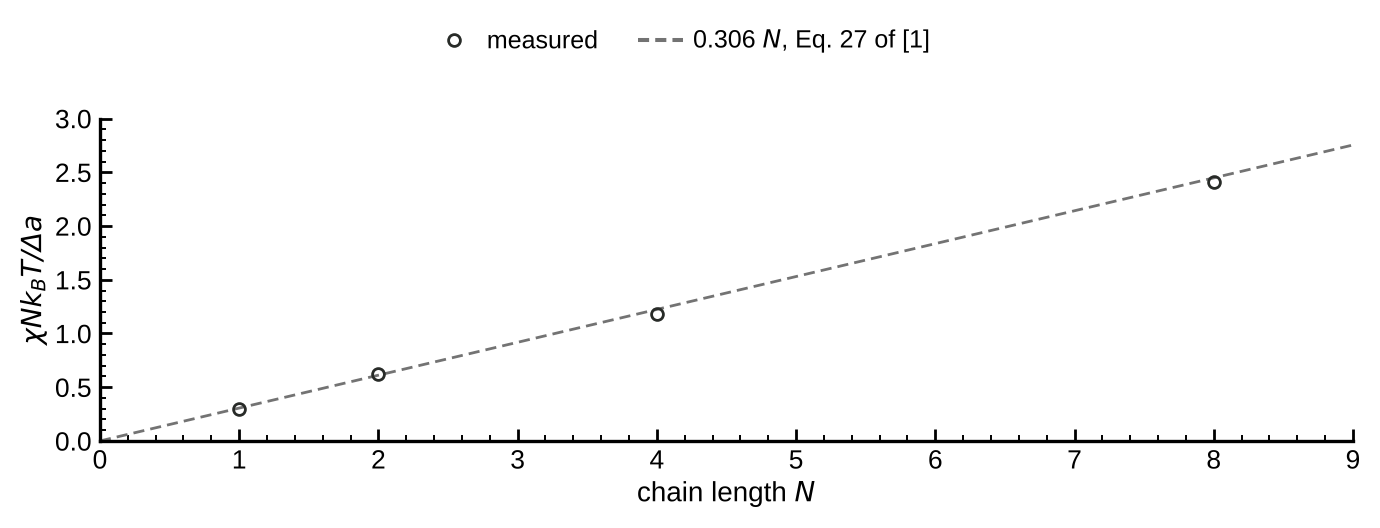

,Δa,minority fraction φ,χN,χ / Δa
N,,,,
1,12.0,0.0340,3.5898,0.2991
2,8.0,0.0073,4.9902,0.3119
4,4.0,0.0097,4.7129,0.2946
8,2.0,0.0088,4.8129,0.3008


In [11]:
delta_of = {1: 12.0, 2: 8.0, 4: 4.0, 8: 2.0}
lengths = np.array(list(polymer))
ratio = np.array([polymer[chain][3] / delta_of[chain] for chain in lengths])

fig, axes = one_panel()
axes.plot([0, 9], [0, 9 * 0.306], color='0.45', lw=1.0, ls='--')
axes.plot(lengths, ratio * lengths, 'o', color=C['ink'], mfc='none', mew=1.0)
axes.set_xlim(0, 9)
axes.set_ylim(0, 3)
axes.set_xlabel('chain length $N$')
axes.set_ylabel(r'$\chi N k_BT / \Delta a$')
top_legend(fig, [Line2D([], [], color=C['ink'], marker='o', mfc='none', ls='none', label='measured'),
                 Line2D([], [], color='0.45', ls='--', label='0.306 $N$, Eq. 27 of [1]')])
fig.savefig(FIGURES / 'chi_chains.pdf')
plt.show()

pd.DataFrame({'Δa': [delta_of[chain] for chain in lengths], 'minority fraction φ': [polymer[c][2] for c in lengths],
              'χN': [polymer[c][3] * c for c in lengths], 'χ / Δa': ratio},
             index=pd.Index(lengths, name='N')).round(4)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Chains (Figure 4).** χ/Δa is 0.299 for single beads and 0.312, 0.295 and 0.301 for N = 2, 4 and 8,
  against 0.286 and 0.306 in [1]. χN grows with N at the same Δa, so a repulsion that cannot keep single beads apart
  separates chains: at Δa = 2 the 8-bead chains form two phases with φ = 0.009. The slab runs are short, so the
  numbers scatter by a few percent; the trend, χ nearly independent of N, is the result of [1].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6B5B95; color:#ffffff; padding:8px 14px; border-radius:6px;">Spinodal decomposition<br><span style="font-size:0.72em; font-weight:normal;">a random A/B mixture at Δa = 15</span></h2>

A random mixture inside the spinodal is unstable: domains appear everywhere at once and then coarsen. A box of
10 × 10 × 10 r<sub>C</sub>³ with 3000 beads, half A and half B at random, runs at Δa = 15 (χ ≈ 4.3, far above
χ<sub>crit</sub> = 2) for 2000 steps (80 τ).

**Figure 5.** Spinodal decomposition at Δa = 15: beads in a slice 4 < z < 6 through the middle of the box at four
times. `figures/spinodal.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code runs the random mixture, draws Figure 5 (<code>figures/spinodal.pdf</code>) and gives the fraction of like pairs at four times.</div>

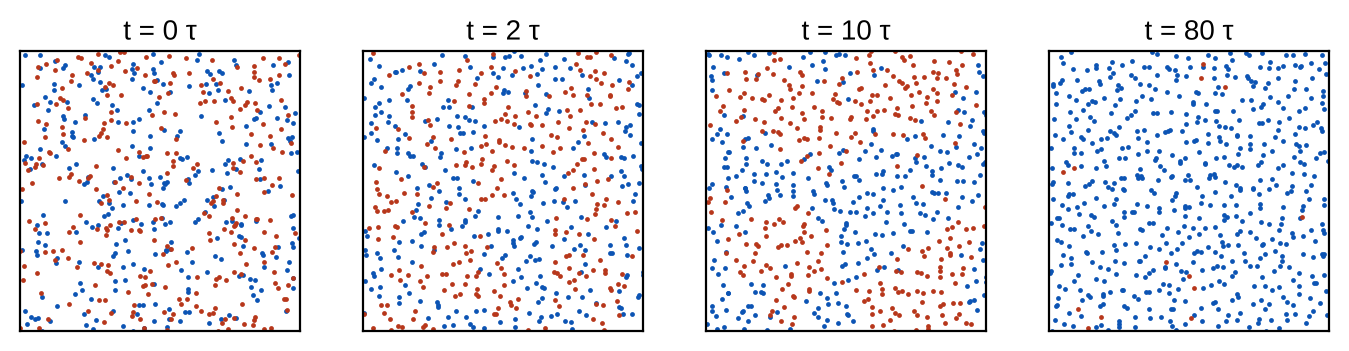

,fraction of like pairs within r_C
time (τ),
0.0,0.499
2.0,0.644
10.0,0.751
80.0,0.890


In [12]:
box3 = np.array([10.0, 10.0, 10.0])
count3 = int(RHO * np.prod(box3))
rng = np.random.default_rng(5)
pos3 = rng.random((count3, 3)) * box3
vel3 = rng.standard_normal((count3, 3))
vel3 -= vel3.mean(axis=0)
types3 = (rng.random(count3) < 0.5).astype(int)
snapshots = {0: pos3 % box3}
frames = [pos3 % box3]                               # positions every 2 tau, for the 3D movie


def keep(step, pos_now, vel_now):
    frames.append(pos_now % box3)
    if step in (50, 250, 2000):
        snapshots[step] = pos_now % box3


run(pos3, vel3, types3, repulsion(15.0), box3, 2000, every=50, callback=keep, seed=6)

fig = plt.figure(figsize=(7.0, 2.6))
for column, step in enumerate([0, 50, 250, 2000]):
    axes = fig.add_axes([0.03 + 0.245 * column, 0.08, 0.2, 0.2 * 7.0 / 2.6])
    x = snapshots[step]
    middle = (x[:, 2] > 4) & (x[:, 2] < 6)          # a slice through the middle of the box
    for kind, color in [(0, C['A']), (1, C['B'])]:
        mask = middle & (types3 == kind)
        axes.scatter(x[mask, 0], x[mask, 1], s=3, color=color, lw=0)
    axes.set_xlim(0, 10)
    axes.set_ylim(0, 10)
    axes.set_aspect('equal')
    axes.set_xticks([])
    axes.set_yticks([])
    for side in axes.spines.values():                # a thin frame around the slice
        side.set_visible(True)
        side.set_linewidth(0.8)
    panel_title(axes, f't = {step * DT:g} τ')
fig.savefig(FIGURES / 'spinodal.pdf')
plt.show()

like = []
for step in sorted(snapshots):
    pairs = cKDTree(snapshots[step], boxsize=box3).query_pairs(1.0, output_type='ndarray')
    like.append(np.mean(types3[pairs[:, 0]] == types3[pairs[:, 1]]))
pd.DataFrame({'fraction of like pairs within r_C': like},
             index=pd.Index([step * DT for step in sorted(snapshots)], name='time (τ)')).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 1.** Spinodal decomposition at Δa = 15 over 80 τ, one frame every 4 τ (A blue, B red).

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code plays the run as a 3D movie (Viewer 1).</div>

In [ ]:
symbols = np.where(types3 == 0, 'N', 'O')
movie = [Atoms(list(symbols), positions=x, cell=box3) for x in frames]
show_3d(movie, {'N': C['A'], 'O': C['B']}, every=2, radius=0.3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Spinodal decomposition (Figure 5).** Within a few τ the random mixture breaks into A-rich and B-rich domains,
  which then coarsen: the fraction of like pairs grows from 0.50 at the start to 0.64 at 2 τ, 0.75 at 10 τ
  and 0.89 at 80 τ. In a box this small the domains soon span the box and end as slabs or cylinders; at 80 τ the slice of
  Figure 5 lies inside one A-rich slab. The
  Cahn–Hilliard equation describes the same coarsening on the continuum level.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#795548; color:#ffffff; padding:8px 14px; border-radius:6px;">The coating model<br><span style="font-size:0.72em; font-weight:normal;">the repulsions of the four bead types and their χ</span></h2>

The coating models of [4–6] have four bead types: A (starch, hydrophilic), B (a random copolymer of styrene, 42 wt%,
and n-butyl acrylate, 58 wt%, hydrophobic), C (cellulose substrate) and D (water). All self repulsions are
a<sub>ii</sub> = 25. The cross terms come from χ values computed with atomistic MD, from the cohesive energies of the
pure components and of their mixtures (chapter 3 of [4]):

$$\chi_{ij} = \frac{V_{DPD}\,\Delta E^{mix}_{ij}}{RT}, \qquad \Delta E^{mix}_{ij} = \phi_i\frac{E^{coh}_i}{V_i} + \phi_j\frac{E^{coh}_j}{V_j} - \frac{E^{coh}_{ij}}{V_{ij}},$$

where V<sub>DPD</sub> is the volume of a bead, R the gas constant, E<sup>coh</sup> cohesive energies and V molar volumes
of the pure components i and j and of their mixture ij; χ<sub>ij</sub> then gives a<sub>ij</sub> = 25 + 3.27
χ<sub>ij</sub>. The matrix of [4] (Table 3.1, from [5]), also used in notebook 04:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code gives the repulsions a<sub>ij</sub> of the coating model and their χ<sub>ij</sub> in one table.</div>

In [14]:
names = ['A', 'B', 'C', 'D']
a_coat = np.array([[25.00, 56.15, 25.00, 35.00],
                   [56.15, 25.00, 56.15, 107.0],
                   [25.00, 56.15, 25.00, 35.00],
                   [35.00, 107.0, 35.00, 25.00]])
chi_coat = (a_coat - 25.0) / 3.27

pd.concat({'a_ij (k_BT/r_C)': pd.DataFrame(a_coat, index=names, columns=names),
           'χ_ij = (a_ij − 25) / 3.27': pd.DataFrame(chi_coat, index=names, columns=names).round(2)}, axis=1)

a_ij (k_BT/r_C)                       χ_ij = (a_ij − 25) / 3.27         \
                A       B      C      D                         A      B   
A           25.00   56.15  25.00   35.0                      0.00   9.53   
B           56.15   25.00  56.15  107.0                      9.53   0.00   
C           25.00   56.15  25.00   35.0                      0.00   9.53   
D           35.00  107.00  35.00   25.0                      3.06  25.08   

                
      C      D  
A  0.00   3.06  
B  9.53  25.08  
C  0.00   3.06  
D  3.06   0.00

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **A and the substrate.** a<sub>AC</sub> = 25, so χ<sub>AC</sub> = 0: the starch block and the cellulose substrate
  mix like beads of one kind, and the A block can anchor the copolymer to the substrate.
- **Hydrophilic beads and water.** a<sub>AD</sub> = a<sub>CD</sub> = 35 (χ ≈ 3.1): at this coarse-grained level the
  hydrophilic beads prefer each other and the substrate to water.
- **B and the rest.** a<sub>BD</sub> = 107 (χ ≈ 25.1) and a<sub>AB</sub> = a<sub>BC</sub> = 56.15 (χ ≈ 9.5): the
  hydrophobic block avoids water most of all, then the hydrophilic beads.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6D597A; color:#ffffff; padding:8px 14px; border-radius:6px;">Exercises<br><span style="font-size:0.72em; font-weight:normal;">below the critical point, a higher density, and reading the matrix, with solutions</span></h2>

**Exercise 1. Below the critical point.** For single beads, Flory–Huggins predicts demixing only for χ > 2, that is
Δa > 2/0.286 ≈ 7.0 with Eq. 24 of [1]. Run the slab with Δa = 4 (χ ≈ 1.1) and look at the composition profile. What
happens to the sharp interface of the start?

**Figure 6.** Composition profile of the slab of single beads at Δa = 4 against Δa = 10. The dashed line marks full
mixing. `figures/below_critical.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 1) runs the slab at Δa = 4 and draws Figure 6 (<code>figures/below_critical.pdf</code>); the table gives the fraction of A in the two bulk regions.</div>

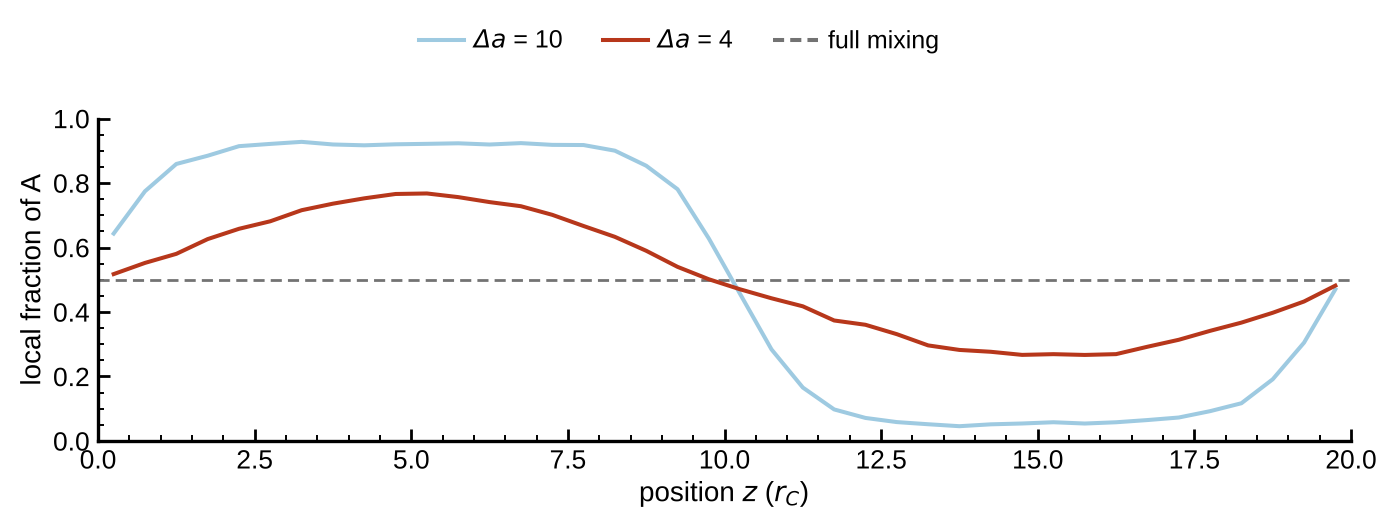

,"fraction of A, lower bulk","fraction of A, upper bulk"
Δa,,
10.0,0.921,0.057
4.0,0.735,0.286


In [15]:
# Solution 1
low = measure_chi(pos0, vel0, types0, repulsion(4.0), box, seed=7)
fraction_low = low[0] / (low[0] + low[1])
fraction_10 = results[10.0][0] / (results[10.0][0] + results[10.0][1])

fig, axes = one_panel()
axes.axhline(0.5, color='0.45', lw=1.0, ls='--')
axes.plot(CENTERS, fraction_10, color=DA_COLORS[1])
axes.plot(CENTERS, fraction_low, color=C['B'])
axes.set_xlim(0, box[2])
axes.set_ylim(0, 1)
axes.set_xlabel(r'position $z$ ($r_C$)')
axes.set_ylabel('local fraction of A')
top_legend(fig, [Line2D([], [], color=DA_COLORS[1], label=r'$\Delta a$ = 10'),
                 Line2D([], [], color=C['B'], label=r'$\Delta a$ = 4'),
                 Line2D([], [], color='0.45', ls='--', label='full mixing')])
fig.savefig(FIGURES / 'below_critical.pdf')
plt.show()

pd.DataFrame({'fraction of A, lower bulk': [fraction_10[BULK_A].mean(), fraction_low[BULK_A].mean()],
              'fraction of A, upper bulk': [fraction_10[BULK_B].mean(), fraction_low[BULK_B].mean()]},
             index=pd.Index([10.0, 4.0], name='Δa')).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 1 (Figure 6).** At Δa = 4 the two halves mix: the fraction of A in the two bulk regions is 0.74 and
  0.29 after 120 τ (0.92 and 0.06 at Δa = 10), the sharp interface of the start has spread over the whole box,
  and the fractions are still moving toward 0.5. The entropy of mixing wins over the A–B repulsion; given more time,
  the profile would become flat.

**Exercise 2. A higher density.** Groot and Madden [3] also used ρ = 5 with a<sub>ii</sub> = 15 (75/ρ), where
a<sub>ij</sub> ≈ a<sub>ii</sub> + 1.45 χ<sub>ij</sub> (their Eq. 8). Measure χ in a slab of 3840 beads at ρ = 5
(8 × 8 × 12 r<sub>C</sub>³) with Δa = 7 and compare with Eqs. 23 and 24 of [1].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 2) runs the slab at ρ = 5 and compares χ with Eqs. 23 and 24 of [1].</div>

In [16]:
# Solution 2
box5 = np.array([8.0, 8.0, 12.0])                    # 3840 beads at rho = 5
count5 = int(5.0 * np.prod(box5))
pos5 = np.random.default_rng(8).random((count5, 3)) * box5
vel5 = np.random.default_rng(9).standard_normal((count5, 3))
vel5 -= vel5.mean(axis=0)
types5 = (pos5[:, 2] > box5[2] / 2).astype(int)
dense = measure_chi(pos5, vel5, types5, repulsion(7.0, a_ii=15.0), box5, nsteps=2500, seed=10)
pd.DataFrame({'χ': [dense[3], 0.689 * 7.0, 2 * 0.101 * 7.0 * 5.0], 'χ / Δa': [dense[3] / 7.0, 0.689, 2 * 0.101 * 5.0]},
             index=['measured, ρ = 5, a_ii = 15, Δa = 7', 'Eq. 24 of [1], ρ = 5', 'Eq. 23 of [1], ρ = 5']).round(3)

,χ,χ / Δa
"measured, ρ = 5, a_ii = 15, Δa = 7",4.937,0.705
"Eq. 24 of [1], ρ = 5",4.823,0.689
"Eq. 23 of [1], ρ = 5",7.070,1.010


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 2.** At ρ = 5, χ/Δa = 0.705, against 0.689 of Eq. 24 and 1.01 of Eq. 23 of [1]. The same Δa gives
  a larger χ at a higher density, but not in proportion to ρ, as Eq. 23 predicts: going from ρ = 3 to 5 multiplies
  χ/Δa by about 2.4, not 5/3. A repulsion from one paper can be reused only at the density it was made for.

**Exercise 3. Reading the matrix.** From the χ values of the coating model, predict where the A and B blocks of a
diblock copolymer lie near a cellulose surface in water: which block touches the surface, which faces the water, and
what sits in the middle? Notebook 04 tests the prediction.

- **Answer 3.** The A block is compatible with the substrate (χ<sub>AC</sub> = 0) and much less incompatible with water
  than B (χ<sub>AD</sub> ≈ 3.1 against χ<sub>BD</sub> ≈ 25.1). So A covers the substrate, B gathers away from the
  water in the middle of the film, and a second A layer faces the water: the layered A–B–A film found for nearly
  symmetric copolymers in [5].

Notebook 03 uses the mapping for diblock copolymer melts, as Groot and Madden did, and notebook 04 puts diblock
copolymers, water and a cellulose-like substrate together with the coating parameters.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#37474F; color:#ffffff; padding:8px 14px; border-radius:6px;">Summary<br><span style="font-size:0.72em; font-weight:normal;">the answers to the four questions</span></h2>

1. **Flory–Huggins.** χ measures the cost of A–B contacts; a symmetric blend demixes above χ<sub>crit</sub> = 2/N, and
   the compositions of the coexisting phases (the binodal) give χ.
2. **Single beads.** The measured χ grows linearly with Δa, χ = 0.296 Δa for χ > 3 (0.286 Δa in [1]), about half of
   the mean-field prediction of Eq. 23 of [1].
3. **Chains.** χ/Δa stays close to 0.3 for chains of 2 to 8 beads (0.295 to 0.312; 0.306 in [1]), so
   a<sub>ij</sub> ≈ a<sub>ii</sub> + 3.27 χ<sub>ij</sub> holds for polymers at ρ = 3, while χN, and with it the drive
   to demix, grows with N.
4. **Spinodal decomposition and the coating model.** At Δa = 15 a random mixture forms A-rich and B-rich domains
   within a few τ. In the coating model χ<sub>AC</sub> = 0, χ<sub>AD</sub> ≈ 3.1 and χ<sub>BD</sub> ≈ 25.1 predict a
   layered A–B–A film on the substrate.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6C757D; color:#ffffff; padding:8px 14px; border-radius:6px;">References<br><span style="font-size:0.72em; font-weight:normal;">theory and coating models</span></h2>

1. R. D. Groot and P. B. Warren, *J. Chem. Phys.* **107**, 4423–4435 (1997), https://doi.org/10.1063/1.474784.
2. P. J. Flory, *Principles of Polymer Chemistry* (Cornell University Press, 1953).
3. R. D. Groot and T. J. Madden, *J. Chem. Phys.* **108**, 8713–8724 (1998), https://doi.org/10.1063/1.476300.
4. K. Hasheminejad, *Computational modelling of block copolymer surface coatings at multiple length scales*, doctoral thesis (2026), http://urn.fi/URN:ISBN:978-952-64-2955-7.
5. A. Scacchi, K. Hasheminejad, S. Javan Nikkhah and M. Sammalkorpi, *J. Colloid Interface Sci.* **640**, 809–819 (2023).
6. K. Hasheminejad et al., *Appl. Surf. Sci.* **640**, 158324 (2023).

</div>